In [1]:
#Cell 1: check the GPU
!pip install -q medmnist
import torch, time, numpy as np
print(torch.__version__, torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

# ✅ You should see True and Tesla T4.

2.11.0+cu130 True
Tesla T4


In [2]:
#Cell 2: download the data (takes a few minutes)
from medmnist import PathMNIST, INFO
print(INFO['pathmnist']['label'])
train = PathMNIST(split='train', download=True, size=64)
val   = PathMNIST(split='val',   download=True, size=64)
test  = PathMNIST(split='test',  download=True, size=64)
Xtr, ytr = train.imgs, train.labels.ravel()
Xva, yva = val.imgs, val.labels.ravel()
Xte, yte = test.imgs, test.labels.ravel()
print(Xtr.shape, Xva.shape, Xte.shape)

#You should see about (89996, 64, 64, 3).

{'0': 'adipose', '1': 'background', '2': 'debris', '3': 'lymphocytes', '4': 'mucus', '5': 'smooth muscle', '6': 'normal colon mucosa', '7': 'cancer-associated stroma', '8': 'colorectal adenocarcinoma epithelium'}


100%|██████████| 1.07G/1.07G [05:19<00:00, 3.35MB/s]


(89996, 64, 64, 3) (10004, 64, 64, 3) (7180, 64, 64, 3)


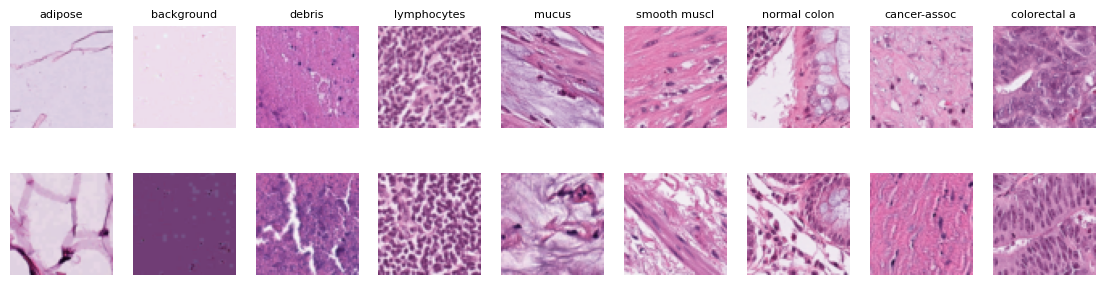

In [3]:
#Cell 3: define the labels and look at the images
SKIP = [0, 1, 2, 4]   # adipose, background, debris, mucus -> nothing to assess
SUSPICIOUS = 8        # tumor epithelium
def gate_labels(y): return (~np.isin(y, SKIP)).astype(np.int64)   # 1 = tissue worth assessing
def cls_labels(y):  return (y == SUSPICIOUS).astype(np.int64)      # 1 = suspicious

import matplotlib.pyplot as plt
names = INFO['pathmnist']['label']
fig, ax = plt.subplots(2, 9, figsize=(14, 3.5))
for c in range(9):
    idx = np.where(ytr == c)[0][:2]
    for r in range(2):
        ax[r, c].imshow(Xtr[idx[r]]); ax[r, c].axis('off')
    ax[0, c].set_title(names[str(c)][:12], fontsize=8)
plt.show()
#✅ You should see a grid of tissue images. Take a screenshot for your README.


In [4]:
#Cell 4: helper functions (just run it)
import torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
dev = 'cuda'
MEAN = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1,3,1,1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1,3,1,1)

def loader(X, y, bs=256, shuffle=False):
    ds = TensorDataset(torch.from_numpy(X).permute(0,3,1,2).contiguous(), torch.from_numpy(y))
    return DataLoader(ds, batch_size=bs, shuffle=shuffle, num_workers=2, pin_memory=True)

def prep(x):
    x = x.to(dev, non_blocking=True).float() / 255.
    return (x - MEAN) / STD

@torch.no_grad()
def predict(model, dl):
    model.eval(); out = []
    for x, _ in dl:
        with torch.autocast('cuda', dtype=torch.float16):
            out.append(model(prep(x)).float().softmax(1).cpu())
    return torch.cat(out)

def train_model(model, tr, va, epochs=5, lr=1e-3):
    model = model.to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs*len(tr))
    scaler = torch.amp.GradScaler('cuda')
    for ep in range(epochs):
        model.train(); t0 = time.time()
        for x, y in tr:
            x, y = prep(x), y.to(dev)
            if torch.rand(1) < 0.5: x = x.flip(3)   # random flips = augmentation
            if torch.rand(1) < 0.5: x = x.flip(2)
            with torch.autocast('cuda', dtype=torch.float16):
                loss = F.cross_entropy(model(x), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        acc = (predict(model, va).argmax(1) == va.dataset.tensors[1]).float().mean()
        print(f'epoch {ep+1}: loss {loss.item():.3f}  val acc {acc:.4f}  ({time.time()-t0:.0f}s)')
    return model


In [5]:
#the fast gate model

#Cell 5: train the gate
class TinyGate(nn.Module):
    def __init__(self):
        super().__init__()
        def block(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False),
                                              nn.BatchNorm2d(o), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.f = nn.Sequential(block(3,16), block(16,32), block(32,64), block(64,64))
        self.head = nn.Linear(64, 2)
    def forward(self, x):
        return self.head(self.f(x).mean((2,3)))

gate_tr = loader(Xtr, gate_labels(ytr), shuffle=True)
gate_va = loader(Xva, gate_labels(yva))
gate = train_model(TinyGate(), gate_tr, gate_va, epochs=5, lr=3e-3)
print('gate parameters:', sum(p.numel() for p in gate.parameters()))



epoch 1: loss 0.194  val acc 0.8374  (11s)
epoch 2: loss 0.113  val acc 0.9308  (6s)
epoch 3: loss 0.085  val acc 0.9074  (6s)
epoch 4: loss 0.053  val acc 0.9805  (6s)
epoch 5: loss 0.032  val acc 0.9879  (6s)
gate parameters: 60818


In [6]:
#Cell 6: choose the gate threshold
from sklearn.metrics import confusion_matrix
p_gate = predict(gate, loader(Xte, gate_labels(yte)))[:,1].numpy()
yt = gate_labels(yte)
for t in [0.5, 0.2, 0.1, 0.05]:
    keep = p_gate > t
    print(f'threshold {t}: tissue kept {keep[yt==1].mean():.2%} | empty frames skipped {(~keep[yt==0]).mean():.2%}')
#✅ Write down the threshold where "tissue kept" is 99% or higher. The gate must almost never throw away real tissue, because a skipped tumor frame is a missed cancer. This is the false-negative point you raised with Alex.


threshold 0.5: tissue kept 94.97% | empty frames skipped 86.93%
threshold 0.2: tissue kept 96.82% | empty frames skipped 78.22%
threshold 0.1: tissue kept 97.46% | empty frames skipped 71.03%
threshold 0.05: tissue kept 98.07% | empty frames skipped 63.95%


In [7]:
#Stage 2, the classifier

#Cell 7: train the suspicious-vs-benign classifier (a pretrained ResNet50, which is transfer learning)

import torchvision
m_tr, m_va, m_te = ~np.isin(ytr, SKIP), ~np.isin(yva, SKIP), ~np.isin(yte, SKIP)
cls_tr = loader(Xtr[m_tr], cls_labels(ytr[m_tr]), bs=128, shuffle=True)
cls_va = loader(Xva[m_va], cls_labels(yva[m_va]), bs=128)
m = torchvision.models.resnet50(weights='DEFAULT')
m.fc = nn.Linear(m.fc.in_features, 2)
clf = train_model(m, cls_tr, cls_va, epochs=4, lr=5e-4)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 207MB/s]


epoch 1: loss 0.011  val acc 0.9840  (27s)
epoch 2: loss 0.009  val acc 0.9944  (27s)
epoch 3: loss 0.000  val acc 0.9974  (28s)
epoch 4: loss 0.000  val acc 0.9981  (27s)


In [8]:
#Cell 8: measure sensitivity and specificity
p_cls = predict(clf, loader(Xte[m_te], cls_labels(yte[m_te]), bs=128))[:,1].numpy()
yt = cls_labels(yte[m_te])
for t in [0.5, 0.3, 0.2, 0.1]:
    tn, fp, fn, tp = confusion_matrix(yt, p_cls > t).ravel()
    print(f'threshold {t}: sensitivity {tp/(tp+fn):.2%} | specificity {tn/(tn+fp):.2%} | missed suspicious: {fn}')


threshold 0.5: sensitivity 97.00% | specificity 97.65% | missed suspicious: 37
threshold 0.3: sensitivity 97.40% | specificity 96.19% | missed suspicious: 32
threshold 0.2: sensitivity 97.89% | specificity 95.77% | missed suspicious: 26
threshold 0.1: sensitivity 98.46% | specificity 94.93% | missed suspicious: 19


✅ Pick a threshold with high sensitivity, so few suspicious frames get missed, and write it down.

📝 Note for your interview story: PathMNIST's test images come from a different hospital than its training images, so test accuracy will be lower than validation accuracy. That's called domain shift, and it's a real problem in medical AI. Mention it in your README. It shows maturity.


In [9]:
#The full pipeline and speed test

#Cell 9: end-to-end accuracy (run this before Cell 10)
GATE_T, CLS_T = 0.1, 0.3   # <-- replace with YOUR thresholds from Cells 6 and 8
p_all = predict(clf, loader(Xte, cls_labels(yte), bs=128))[:,1].numpy()
flag = (p_gate > GATE_T) & (p_all > CLS_T)
sus = yte == SUSPICIOUS
print(f'suspicious frames caught end-to-end: {flag[sus].mean():.2%} ({(~flag[sus]).sum()} missed of {sus.sum()})')
print(f'non-suspicious frames wrongly flagged: {flag[~sus].mean():.2%}')
print(f'frames skipped by gate: {(p_gate <= GATE_T).mean():.2%}')



suspicious frames caught end-to-end: 97.40% (32 missed of 1233)
non-suspicious frames wrongly flagged: 1.95%
frames skipped by gate: 36.49%


In [10]:
#Cell 10: real-time speed test (one frame at a time, like a live microscope)
gate_h = gate.eval().half().to(memory_format=torch.channels_last)
clf_h  = clf.eval().half().to(memory_format=torch.channels_last)
frames = torch.from_numpy(Xte[:1000]).permute(0,3,1,2).contiguous()

def to_gpu(f):
    return ((f.to(dev).float()/255. - MEAN)/STD).half().contiguous(memory_format=torch.channels_last)

@torch.no_grad()
def run(stream, two_stage):
    times, n_cls = [], 0
    for i in range(len(stream)):
        torch.cuda.synchronize(); t0 = time.perf_counter()
        x = to_gpu(stream[i:i+1])
        if not two_stage or gate_h(x).float().softmax(1)[0,1] > GATE_T:
            clf_h(x); n_cls += 1
        torch.cuda.synchronize(); times.append((time.perf_counter()-t0)*1000)
    t = np.array(times)
    return t.mean(), np.percentile(t, 99), n_cls

for name, two in [('classifier on every frame', False), ('gate + classifier', True)]:
    run(frames[:100], two)   # warm-up
    mean, p99, n = run(frames, two)
    print(f'{name}: avg {mean:.2f} ms/frame | p99 {p99:.2f} ms | {1000/mean:.0f} fps | classifier ran on {n}/{len(frames)} frames')
print('Budget at 33 fps = 30.3 ms per frame')


classifier on every frame: avg 6.78 ms/frame | p99 8.66 ms | 148 fps | classifier ran on 1000/1000 frames
gate + classifier: avg 4.95 ms/frame | p99 9.36 ms | 202 fps | classifier ran on 614/1000 frames
Budget at 33 fps = 30.3 ms per frame


In [11]:
#GitHub, README, and resume

torch.save(gate.state_dict(), '/kaggle/working/gate.pt')
torch.save(clf.state_dict(), '/kaggle/working/classifier.pt')
print('Saved. Find the files in the Output panel on the right.')

#To get the notebook onto GitHub from Kaggle: click File → Download notebook. Then in your GitHub repo, click Add file → Upload files and upload the .ipynb file.

Saved. Find the files in the Output panel on the right.


✅ Copy all the numbers from Cells 9 and 10. These are your results. Report them exactly as they come out, even if the speedup is small. On tiny 64-pixel images the difference is modest, and on full-size microscope frames it grows. Say that honestly in the README.
